In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import statsmodels.api as sm
from statsmodels import regression
import statsmodels.stats.diagnostic as smd

plt.style.use("seaborn-v0_8")

CWD = Path.cwd()
if (CWD / "sprint-3").is_dir():
    OUT_DIR = CWD / "sprint-3" / "images"
elif CWD.name == "sprint-3":
    OUT_DIR = CWD / "images"
else:
    OUT_DIR = CWD / "sprint-3" / "images"
OUT_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(42)

pd.set_option("display.precision", 6)
pd.set_option("display.max_rows", 200)


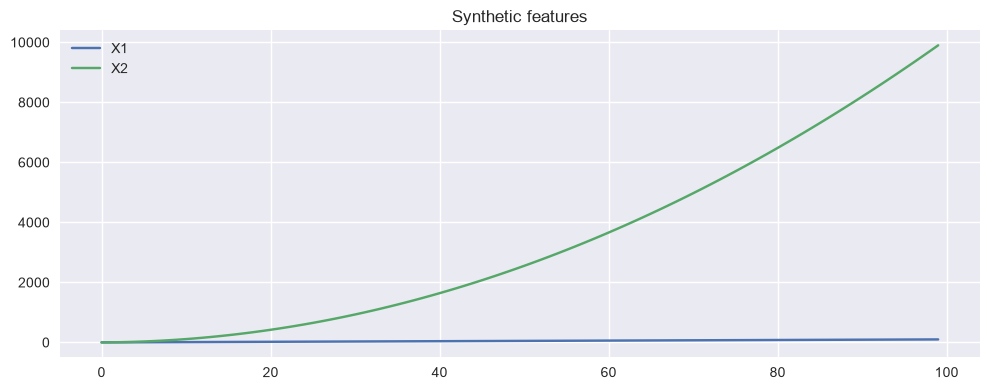

In [2]:
X1 = np.arange(100)

X2 = np.array([i**2 for i in range(100)]) + X1

Y = X1 + X2

plt.figure(figsize=(10, 4))
plt.plot(X1, label="X1")
plt.plot(X2, label="X2")
plt.title("Synthetic features")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "mlr_A1_features.png", dpi=150)
plt.show()


In [3]:
X = sm.add_constant(np.column_stack((X1, X2)))
results = regression.linear_model.OLS(Y, X).fit()
print(results.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.695e+30
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:58:58   Log-Likelihood:                 2430.5
No. Observations:                 100   AIC:                            -4855.
Df Residuals:                      97   BIC:                            -4847.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.137e-13   2.01e-12     -0.057      0.9

In [4]:
X1 = np.arange(100)
X2 = np.array([i**2 for i in range(100)]) - X1
X3 = np.array([np.log(i) for i in range(1, 101)]) + X2
X4 = 5 * X1

Y = 2 * X1 + 0.5 * X2 + 10 * X3 + X4

data = pd.DataFrame(np.column_stack((X1, X2, X3, X4)), columns=["X1", "X2", "X3", "X4"])
response = pd.Series(Y, name="Y")

data.head()


,X1,X2,X3,X4
0,0.0,0.0,0.000000,0.0
1,1.0,0.0,0.693147,5.0
2,2.0,2.0,3.098612,10.0
3,3.0,6.0,7.386294,15.0
4,4.0,12.0,13.609438,20.0


In [6]:
def forward_aic(response: pd.Series, data: pd.DataFrame):
    """Forward stepwise selection using AIC (lower is better)."""
    explanatory = list(data.columns)
    selected = pd.Series(np.ones(data.shape[0]), name="Intercept")
    current_score = np.inf

    while len(explanatory) != 0:
        scores = []
        for idx, element in enumerate(explanatory):
            tmp = pd.concat([selected, data[element]], axis=1)
            result = regression.linear_model.OLS(response, tmp).fit()
            scores.append((result.aic, element, idx))

        scores.sort(key=lambda x: x[0])  
        best_new_score, best_element, best_idx = scores[0]

        if best_new_score < current_score:
            current_score = best_new_score
            explanatory.pop(best_idx)
            selected = pd.concat([selected, data[best_element]], axis=1)
        else:
            break

    model = regression.linear_model.OLS(response, selected).fit()
    return model


model_forward = forward_aic(response, data)
print(model_forward.summary())


                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 2.563e+26
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:59:38   Log-Likelihood:                 1691.3
No. Observations:                 100   AIC:                            -3375.
Df Residuals:                      96   BIC:                            -3364.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   4.366e-11    7.7e-09      0.006      0.9

C:\Users\amelu\AppData\Local\Temp\ipykernel_20704\2949771509.py:11: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  result = regression.linear_model.OLS(response, tmp).fit()
C:\Users\amelu\AppData\Local\Temp\ipykernel_20704\2949771509.py:11: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  result = regression.linear_model.OLS(response, tmp).fit()
C:\Users\amelu\AppData\Local\Temp\ipykernel_20704\2949771509.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = regression.linear_model.OLS(response, selected).fit()


beta_0: 15.982232951417064
beta_1: -2.2151127480086683


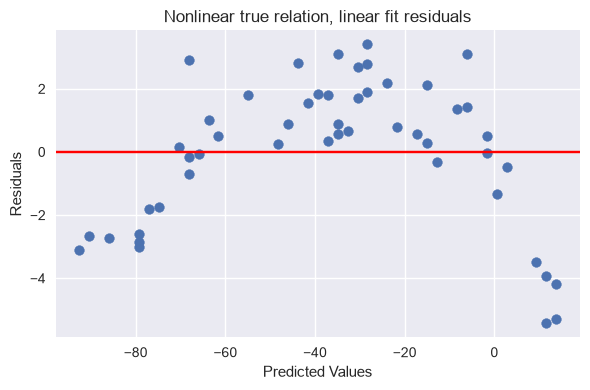

In [7]:
n = 50
X = np.random.randint(0, 50, n)
epsilon = np.random.normal(0, 1, n)

Y_nonlinear = 10 - X**1.2 + epsilon

model = sm.OLS(Y_nonlinear, sm.add_constant(X)).fit()
B0, B1 = model.params
residuals = model.resid

print("beta_0:", B0)
print("beta_1:", B1)

plt.figure(figsize=(6, 4))
plt.scatter(model.predict(), residuals)
plt.axhline(0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Nonlinear true relation, linear fit residuals")
plt.tight_layout()
plt.savefig(OUT_DIR / "residuals_B1_nonlinear.png", dpi=150)
plt.show()


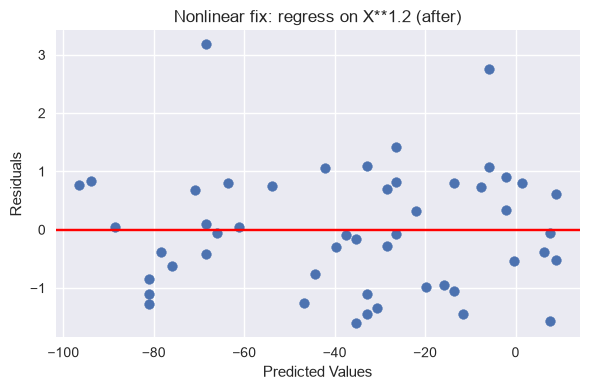

In [8]:
X_nl = X**1.2
model_nl = sm.OLS(Y_nonlinear, sm.add_constant(X_nl)).fit()
residuals_nl = model_nl.resid

plt.figure(figsize=(6, 4))
plt.scatter(model_nl.predict(), residuals_nl)
plt.axhline(0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Nonlinear fix: regress on X**1.2 (after)")
plt.tight_layout()
plt.savefig(OUT_DIR / "residuals_B1_after_transform.png", dpi=150)
plt.show()


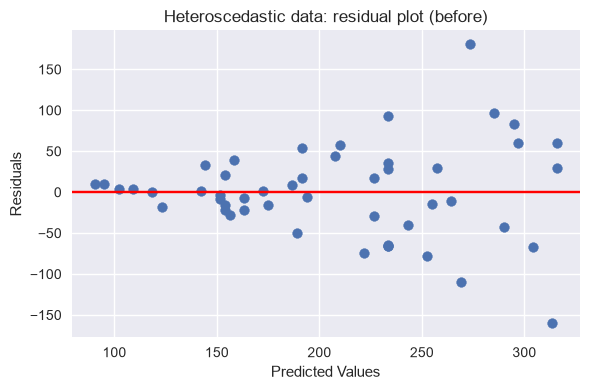

Breusch–Pagan (before)
H0: homoskedasticity (constant variance)
LM stat: 11.745259618509618
LM p-value: 0.0006099839930440068
F stat: 14.737322906032421
F p-value: 0.000361364487822136


In [9]:
n = 50
X = np.random.randint(0, 100, n)
epsilon = np.random.normal(0, 1, n)

Y_heteroscedastic = 100 + 2 * X + epsilon * X

model = sm.OLS(Y_heteroscedastic, sm.add_constant(X)).fit()
residuals = model.resid

plt.figure(figsize=(6, 4))
plt.scatter(model.predict(), residuals)
plt.axhline(0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Heteroscedastic data: residual plot (before)")
plt.tight_layout()
plt.savefig(OUT_DIR / "residuals_B2_before.png", dpi=150)
plt.show()

lm_stat, lm_pvalue, f_stat, f_pvalue = smd.het_breuschpagan(model.resid, model.model.exog)
print("Breusch–Pagan (before)")
print("H0: homoskedasticity (constant variance)")
print("LM stat:", lm_stat)
print("LM p-value:", lm_pvalue)
print("F stat:", f_stat)
print("F p-value:", f_pvalue)


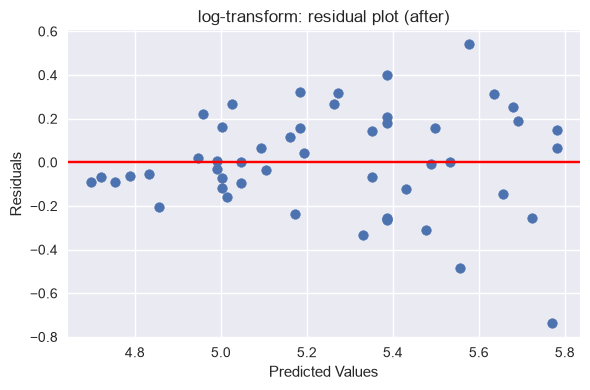

Breusch–Pagan (after log)
H0: homoskedasticity (constant variance)
LM stat: 8.763939686963983
LM p-value: 0.0030724464330192766
F stat: 10.201486315153256
F p-value: 0.0024793467307040813


In [10]:
Y_heteroscedastic_log = np.log(Y_heteroscedastic)

model_log = sm.OLS(Y_heteroscedastic_log, sm.add_constant(X)).fit()
residuals_log = model_log.resid

plt.figure(figsize=(6, 4))
plt.scatter(model_log.predict(), residuals_log)
plt.axhline(0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("log-transform: residual plot (after)")
plt.tight_layout()
plt.savefig(OUT_DIR / "residuals_B2_after_log.png", dpi=150)
plt.show()

lm_stat2, lm_pvalue2, f_stat2, f_pvalue2 = smd.het_breuschpagan(model_log.resid, model_log.model.exog)
print("Breusch–Pagan (after log)")
print("H0: homoskedasticity (constant variance)")
print("LM stat:", lm_stat2)
print("LM p-value:", lm_pvalue2)
print("F stat:", f_stat2)
print("F p-value:", f_pvalue2)


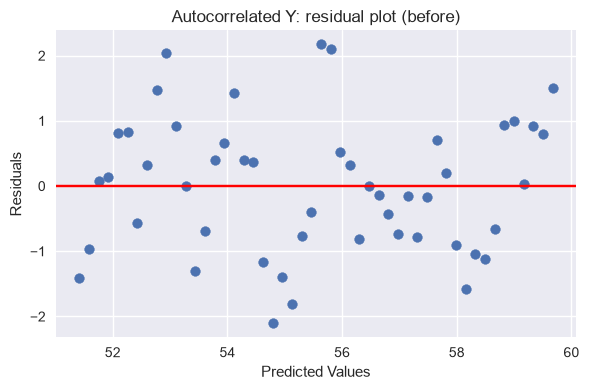

Ljung–Box (before)
H0: no autocorrelation up to lag=10
lb_pvalue by lag:
 1     0.000017
2     0.000048
3     0.000073
4     0.000014
5     0.000005
6     0.000006
7     0.000014
8     0.000031
9     0.000068
10    0.000125
Any p < 0.05? True


In [11]:
n = 50
X = np.linspace(0, n, n)
Y_autocorrelated = np.zeros(n)
Y_autocorrelated[0] = 50

for t in range(1, n):
    Y_autocorrelated[t] = Y_autocorrelated[t-1] + np.random.normal(0, 1)

model = sm.OLS(Y_autocorrelated, sm.add_constant(X)).fit()
residuals = model.resid

plt.figure(figsize=(6, 4))
plt.scatter(model.predict(), residuals)
plt.axhline(0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Autocorrelated Y: residual plot (before)")
plt.tight_layout()
plt.savefig(OUT_DIR / "residuals_B3_before.png", dpi=150)
plt.show()

ljung_before = smd.acorr_ljungbox(residuals, lags=10, return_df=True)
pvals_before = ljung_before["lb_pvalue"]

print("Ljung–Box (before)")
print("H0: no autocorrelation up to lag=10")
print("lb_pvalue by lag:\n", pvals_before.to_string())
print("Any p < 0.05?", bool((pvals_before < 0.05).any()))


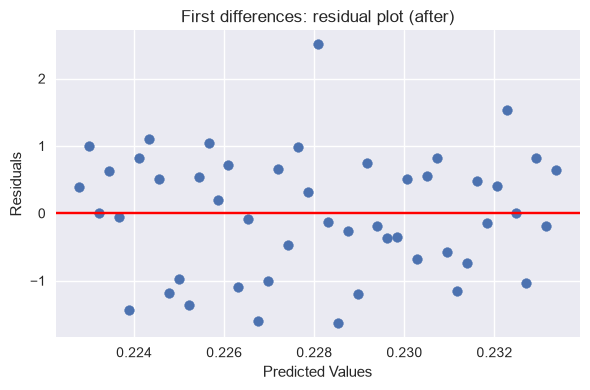

Ljung–Box (after differences)
H0: no autocorrelation up to lag=10
lb_pvalue by lag:
 1     0.591054
2     0.687901
3     0.299967
4     0.089195
5     0.146606
6     0.209729
7     0.108620
8     0.158142
9     0.210826
10    0.280543
Any p < 0.05? False


In [12]:
Y_autocorrelated_diff = np.diff(Y_autocorrelated)

model_diff = sm.OLS(Y_autocorrelated_diff, sm.add_constant(X[1:])).fit()
residuals_diff = model_diff.resid

plt.figure(figsize=(6, 4))
plt.scatter(model_diff.predict(), residuals_diff)
plt.axhline(0, color="red")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("First differences: residual plot (after)")
plt.tight_layout()
plt.savefig(OUT_DIR / "residuals_B3_after_diff.png", dpi=150)
plt.show()

ljung_after = smd.acorr_ljungbox(residuals_diff, lags=10, return_df=True)
pvals_after = ljung_after["lb_pvalue"]

print("Ljung–Box (after differences)")
print("H0: no autocorrelation up to lag=10")
print("lb_pvalue by lag:\n", pvals_after.to_string())
print("Any p < 0.05?", bool((pvals_after < 0.05).any()))
